# So sánh Pipeline OCR: U-Net Denoising vs Traditional Preprocessing

## Mục tiêu
So sánh **2 pipeline tiền xử lý** ảnh văn bản nhiễu trước khi OCR:

| Pipeline | Mô tả |
|----------|-------|
| **Traditional** | NlMeans Denoise → CLAHE → Adaptive Threshold → Morphological Cleanup |
| **U-Net DAE** | Mô hình U-Net Denoising Autoencoder đã huấn luyện trên NoisyOffice |

## OCR Models
| # | Model | Kiểu kiến trúc |
|---|-------|----------------|
| 1 | **Tesseract v5** | LSTM-based |
| 2 | **PaddleOCR** | DB + PP-OCRv4 |
| 3 | **TrOCR** | ViT Encoder + GPT-2 Decoder |

## Dataset
NoisyOffice — 216 ảnh nhiễu mô phỏng (simulated noisy) + 54 ảnh sạch chuẩn (clean ground truth images)

## 1. Setup & Installation

In [1]:
# Cai dat cac thu vien can thiet
!apt-get update -qq > /dev/null 2>&1
!apt-get install -y -qq tesseract-ocr tesseract-ocr-eng > /dev/null 2>&1
print('Tesseract installed')

!pip install -q pytesseract paddlepaddle-gpu "paddleocr<3.0.0" \
    transformers jiwer editdistance tqdm Pillow opencv-python-headless 2>/dev/null
print('Python packages installed')

# Fix xung dot cuDNN giua PaddlePaddle va PyTorch
!pip uninstall -y nvidia-cudnn-cu11 2>/dev/null
print('Cleaned cuDNN conflicts')

Tesseract installed
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 758.9/758.9 MB 596.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.5/65.5 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 104.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 95.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 338.3/338.3 kB 23.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 17.6 MB/s eta 0:00:00
Python packages installed
Cleaned cuDNN conflicts


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os, glob, re, time, json, warnings
warnings.filterwarnings('ignore')

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
import pandas as pd
from collections import defaultdict

# OCR engines
import pytesseract
import torch
import torch.nn as nn
from paddleocr import PaddleOCR
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

# Metrics
import editdistance as ed
from jiwer import wer as jiwer_wer

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cuda


## 2. Mount Google Drive & Load Dataset

In [4]:
DATASET_ROOT = '/content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/NoisyOffice'
SIMULATED_NOISY = os.path.join(DATASET_ROOT, 'SimulatedNoisyOffice', 'simulated_noisy_images_grayscale')
CLEAN_BINARY    = os.path.join(DATASET_ROOT, 'SimulatedNoisyOffice', 'clean_images_binaryscale')
REAL_NOISY      = os.path.join(DATASET_ROOT, 'RealNoisyOffice', 'real_noisy_images_grayscale')
UNET_MODEL_PATH = '/content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/NoisyOffice_Models/best_unet_noisyoffice.pth'
OUTPUT_DIR      = '/content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/unet_vs_trad_results'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Verify
for name, path in [('Simulated Noisy', SIMULATED_NOISY), ('Clean Binary', CLEAN_BINARY),
                    ('Real Noisy', REAL_NOISY), ('U-Net Model', UNET_MODEL_PATH)]:
    if os.path.exists(path):
        print(f'[OK] {name}')
    else:
        print(f'[FAIL] {name}: NOT FOUND!')

[OK] Simulated Noisy
[OK] Clean Binary
[OK] Real Noisy
[OK] U-Net Model


## 3. Dinh nghia U-Net Model & Patch-based Inference

In [5]:
# ===== KIEN TRUC U-NET (giong het file huan luyen) =====
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x): return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=1, out_ch=1, base_ch=64):
        super().__init__()
        c = base_ch
        self.enc1 = DoubleConv(in_ch, c)
        self.enc2 = DoubleConv(c, c*2)
        self.enc3 = DoubleConv(c*2, c*4)
        self.enc4 = DoubleConv(c*4, c*8)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(c*8, c*16)
        self.up4 = nn.ConvTranspose2d(c*16, c*8, 2, stride=2)
        self.dec4 = DoubleConv(c*16, c*8)
        self.up3 = nn.ConvTranspose2d(c*8, c*4, 2, stride=2)
        self.dec3 = DoubleConv(c*8, c*4)
        self.up2 = nn.ConvTranspose2d(c*4, c*2, 2, stride=2)
        self.dec2 = DoubleConv(c*4, c*2)
        self.up1 = nn.ConvTranspose2d(c*2, c, 2, stride=2)
        self.dec1 = DoubleConv(c*2, c)
        self.out_conv = nn.Conv2d(c, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return torch.sigmoid(self.out_conv(d1))

# ===== NAP MODEL DA TRAIN =====
unet_model = UNet(in_ch=1, out_ch=1, base_ch=64).to(DEVICE)
unet_model.load_state_dict(torch.load(UNET_MODEL_PATH, map_location=DEVICE))
unet_model.eval()
print('U-Net model loaded successfully!')

# ===== PATCH-BASED INFERENCE (giu nguyen do phan giai) =====
def unet_denoise(img_gray, patch_size=256, overlap=64):
    """Chay U-Net tren tung patch roi ghep lai."""
    H, W = img_gray.shape
    step = patch_size - overlap
    pad_h = (step - (H % step)) % step + overlap
    pad_w = (step - (W % step)) % step + overlap
    img_padded = np.pad(img_gray, ((0, pad_h), (0, pad_w)), mode='reflect')
    H_pad, W_pad = img_padded.shape
    output = np.zeros((H_pad, W_pad), dtype=np.float64)
    count  = np.zeros((H_pad, W_pad), dtype=np.float64)

    with torch.no_grad():
        for y in range(0, H_pad - patch_size + 1, step):
            for x in range(0, W_pad - patch_size + 1, step):
                patch = img_padded[y:y+patch_size, x:x+patch_size]
                t = torch.from_numpy(patch).float().unsqueeze(0).unsqueeze(0) / 255.0
                t = t.to(DEVICE)
                pred = unet_model(t).squeeze().cpu().numpy()
                output[y:y+patch_size, x:x+patch_size] += pred
                count[y:y+patch_size, x:x+patch_size]  += 1.0

    output = output / np.maximum(count, 1.0)
    output = output[:H, :W]
    return (output * 255).clip(0, 255).astype(np.uint8)

U-Net model loaded successfully!


## 4. Traditional Preprocessing Pipeline

In [6]:
def preprocess_traditional(img):
    """Pipeline truyen thong: NlMeans → Background Norm → CLAHE → Binarize → Morpho."""
    if len(img.shape) == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    denoised = cv2.fastNlMeansDenoising(img, h=12, templateWindowSize=7, searchWindowSize=21)
    bg_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (51, 51))
    background = cv2.morphologyEx(denoised, cv2.MORPH_CLOSE, bg_kernel)
    normalized = 255 - cv2.absdiff(denoised, background)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    enhanced = clahe.apply(normalized)
    binary = cv2.adaptiveThreshold(enhanced, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY, 25, 15)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2, 2))
    cleaned = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
    cleaned = cv2.morphologyEx(cleaned, cv2.MORPH_CLOSE, kernel)
    return {'enhanced': enhanced, 'cleaned': cleaned}

print('Traditional preprocessing defined.')

Traditional preprocessing defined.


## 5. Helper Functions

In [7]:
def parse_filename(filename):
    basename = os.path.splitext(os.path.basename(filename))[0]
    match = re.match(r'Font([fLn])([rst])([em])_(Noise([cfwp])|Clean)_([A-Z]{2})', basename)
    if not match:
        return None
    size_map  = {'f': 'footnote', 'n': 'normal', 'L': 'large'}
    type_map  = {'r': 'roman', 's': 'sans-serif', 't': 'typewriter'}
    noise_map = {'c': 'coffee', 'f': 'folded', 'w': 'wrinkled', 'p': 'footprint'}
    return {
        'font_size': size_map.get(match.group(1), match.group(1)),
        'font_type': type_map.get(match.group(2), match.group(2)),
        'noise_type': noise_map.get(match.group(5), 'clean'),
        'split': match.group(6),
    }

def get_clean_key(noisy_fname):
    return re.sub(r'Noise[cfwp]', 'Clean', noisy_fname)

def compute_cer(pred, ref):
    if len(ref) == 0: return 1.0 if len(pred) > 0 else 0.0
    return ed.eval(pred, ref) / len(ref)

def compute_wer_safe(pred, ref):
    if not ref.strip(): return 1.0 if pred.strip() else 0.0
    try: return jiwer_wer(ref, pred)
    except: return 1.0

def normalize_text(text):
    text = re.sub(r'[^a-zA-Z0-9\s.,;:!?\'\"()-]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.lower()

print('Helpers defined.')

Helpers defined.


## 6. Ground Truth Generation

In [8]:
print('Initializing PaddleOCR for GT generation...')
paddle_gt = PaddleOCR(use_angle_cls=True, lang='en', use_gpu=True, show_log=False)
print('PaddleOCR ready')

clean_files = sorted(glob.glob(os.path.join(CLEAN_BINARY, '*.png')))
ground_truth = {}

print(f'Generating GT from {len(clean_files)} clean images...')
for fpath in tqdm(clean_files, desc='Ground Truth'):
    fname = os.path.basename(fpath)
    try:
        result = paddle_gt.ocr(fpath, cls=True)
        if result and result[0]:
            sorted_lines = sorted(result[0], key=lambda x: x[0][0][1])
            text = '\n'.join(line[1][0] for line in sorted_lines)
        else:
            text = ''
    except Exception as e:
        text = ''
    ground_truth[fname] = text

gt_valid = sum(1 for v in ground_truth.values() if v.strip())
print(f'GT generated: {gt_valid}/{len(clean_files)} images have text')

Initializing PaddleOCR for GT generation...
download https://paddleocr.bj.bcebos.com/PP-OCRv3/english/en_PP-OCRv3_det_infer.tar to /root/.paddleocr/whl/det/en/en_PP-OCRv3_det_infer/en_PP-OCRv3_det_infer.tar


100%|██████████| 3910/3910 [00:01<00:00, 1999.80it/s]


download https://paddleocr.bj.bcebos.com/PP-OCRv4/english/en_PP-OCRv4_rec_infer.tar to /root/.paddleocr/whl/rec/en/en_PP-OCRv4_rec_infer/en_PP-OCRv4_rec_infer.tar


100%|██████████| 10000/10000 [00:02<00:00, 3423.53it/s]


download https://paddleocr.bj.bcebos.com/dygraph_v2.0/ch/ch_ppocr_mobile_v2.0_cls_infer.tar to /root/.paddleocr/whl/cls/ch_ppocr_mobile_v2.0_cls_infer/ch_ppocr_mobile_v2.0_cls_infer.tar


100%|██████████| 2138/2138 [00:18<00:00, 115.22it/s]

[2026/07/09 11:26:39] ppocr WARNING: The first GPU is used for inference by default, GPU ID: 0


[2026/07/09 11:26:40] ppocr WARNING: The first GPU is used for inference by default, GPU ID: 0
[2026/07/09 11:26:42] ppocr WARNING: The first GPU is used for inference by default, GPU ID: 0
PaddleOCR ready
Generating GT from 54 clean images...


Ground Truth:   0%|          | 0/54 [00:00<?, ?it/s]

GT generated: 54/54 images have text


## 7. OCR Model Wrappers

In [9]:
# --- TESSERACT ---
def ocr_tesseract(image):
    config = '--oem 3 --psm 6 -l eng'
    if isinstance(image, np.ndarray):
        image = Image.fromarray(image)
    return pytesseract.image_to_string(image, config=config).strip()

# --- PADDLEOCR ---
print('Initializing PaddleOCR for inference...')
paddle_ocr = PaddleOCR(use_angle_cls=True, lang='en', use_gpu=True, show_log=False, det_db_thresh=0.3)
print('PaddleOCR ready')

def ocr_paddleocr(image_path):
    try:
        result = paddle_ocr.ocr(image_path, cls=True)
        if result and result[0]:
            sorted_lines = sorted(result[0], key=lambda x: x[0][0][1])
            return '\n'.join(line[1][0] for line in sorted_lines)
    except: pass
    return ''

# --- TROCR ---
print('Loading TrOCR (microsoft/trocr-large-printed)...')
trocr_processor = TrOCRProcessor.from_pretrained('microsoft/trocr-large-printed')
trocr_model = VisionEncoderDecoderModel.from_pretrained('microsoft/trocr-large-printed', device_map='auto')
trocr_model.eval()
print('TrOCR loaded!')

def segment_text_lines(img, min_height=10):
    if len(img.shape) == 3: img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, bw = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (img.shape[1]//2, 1))
    dilated = cv2.dilate(bw, kernel, iterations=1)
    contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lines = []
    for cnt in contours:
        x, y, w, h = cv2.boundingRect(cnt)
        if h >= min_height and w > 20:
            lines.append((y, x, y+h, x+w))
    lines.sort(key=lambda r: r[0])
    return lines

def ocr_trocr(image):
    try:
        if isinstance(image, str):
            img = cv2.imread(image, cv2.IMREAD_GRAYSCALE)
        else:
            img = image.copy()
        lines = segment_text_lines(img)
        if not lines:
            return ''
        results = []
        for y1, x1, y2, x2 in lines:
            crop = img[y1:y2, x1:x2]
            pil = Image.fromarray(crop).convert('RGB')
            inputs = trocr_processor(images=pil, return_tensors='pt')
            pixel_values = inputs.pixel_values.to(next(trocr_model.parameters()).device)
            ids = trocr_model.generate(pixel_values, max_new_tokens=256)
            text = trocr_processor.batch_decode(ids, skip_special_tokens=True)[0]
            results.append(text)
        return '\n'.join(results)
    except Exception as e:
        return f'[ERROR: {e}]'

print('All OCR models ready!')

Initializing PaddleOCR for inference...
[2026/07/09 11:27:15] ppocr WARNING: The first GPU is used for inference by default, GPU ID: 0
[2026/07/09 11:27:16] ppocr WARNING: The first GPU is used for inference by default, GPU ID: 0
[2026/07/09 11:27:17] ppocr WARNING: The first GPU is used for inference by default, GPU ID: 0
PaddleOCR ready
Loading TrOCR (microsoft/trocr-large-printed)...


preprocessor_config.json:   0%|          | 0.00/224 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

...

model.safetensors:   0%|          | 0.00/2.43G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/632 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-large-printed
Key                                                 | Status     | 
----------------------------------------------------+------------+-
decoder.model.decoder.embed_positions._float_tensor | UNEXPECTED | 
encoder.pooler.dense.bias                           | MISSING    | 
encoder.pooler.dense.weight                         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

TrOCR loaded!
All OCR models ready!


## 8. Chạy Pipeline: U-Net vs Traditional vs Raw

Với mỗi ảnh nhiễu, ta chạy OCR trên **3 phiên bản**:
1. **Raw**: Ảnh nhiễu gốc (không tiền xử lý)
2. **Traditional**: Tiền xử lý truyền thống (NlMeans + CLAHE + Binarize)
3. **U-Net**: Tiền xử lý bằng mô hình U-Net đã train

In [10]:
ocr_models = {
    'Tesseract': ocr_tesseract,
    'PaddleOCR': ocr_paddleocr,
    'TrOCR':     ocr_trocr,
}

pipelines = ['Raw', 'Traditional', 'UNet']

noisy_files = sorted(glob.glob(os.path.join(SIMULATED_NOISY, '*.png')))
print(f'Total noisy images: {len(noisy_files)}')

all_results = []  # list of dicts

for idx, fpath in enumerate(tqdm(noisy_files, desc='Processing')):
    fname = os.path.basename(fpath)
    meta = parse_filename(fname)
    if not meta:
        continue

    clean_key = get_clean_key(fname)
    if clean_key not in ground_truth or not ground_truth[clean_key].strip():
        continue
    gt_text = normalize_text(ground_truth[clean_key])

    # Doc anh goc
    img_raw = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)

    # Tao 3 phien ban tien xu ly
    trad = preprocess_traditional(img_raw)
    unet_out = unet_denoise(img_raw)

    # Luu tam anh U-Net ra disk de PaddleOCR doc duoc
    unet_tmp = f'/tmp/unet_{fname}'
    trad_tmp = f'/tmp/trad_{fname}'
    cv2.imwrite(unet_tmp, unet_out)
    cv2.imwrite(trad_tmp, trad['cleaned'])

    for ocr_name, ocr_fn in ocr_models.items():
        for pipe_name in pipelines:
            t0 = time.time()

            if pipe_name == 'Raw':
                if ocr_name in ('PaddleOCR',):
                    text = ocr_fn(fpath)
                else:
                    text = ocr_fn(img_raw)
            elif pipe_name == 'Traditional':
                if ocr_name == 'Tesseract':
                    text = ocr_fn(trad['cleaned'])
                elif ocr_name in ('PaddleOCR',):
                    text = ocr_fn(trad_tmp)
                else:
                    text = ocr_fn(trad['enhanced'])
            else:  # UNet
                if ocr_name in ('PaddleOCR',):
                    text = ocr_fn(unet_tmp)
                else:
                    text = ocr_fn(unet_out)

            elapsed = time.time() - t0
            pred = normalize_text(text)
            cer = compute_cer(pred, gt_text)
            wer = compute_wer_safe(pred, gt_text)

            all_results.append({
                'filename': fname,
                'ocr_model': ocr_name,
                'pipeline': pipe_name,
                'cer': cer,
                'wer': wer,
                'time': elapsed,
                **meta,
            })

df = pd.DataFrame(all_results)
print(f'\nTotal evaluation records: {len(df)}')
df.head()

Total noisy images: 216


Processing:   0%|          | 0/216 [00:00<?, ?it/s]


Total evaluation records: 1944


,filename,ocr_model,pipeline,cer,wer,time,font_size,font_type,noise_type,split
0,FontLre_Noisec_TE.png,Tesseract,Raw,0.323462,0.565217,1.407637,large,roman,coffee,TE
1,FontLre_Noisec_TE.png,Tesseract,Traditional,0.120729,0.463768,1.299140,large,roman,coffee,TE
2,FontLre_Noisec_TE.png,Tesseract,UNet,0.025057,0.144928,1.078833,large,roman,coffee,TE
3,FontLre_Noisec_TE.png,PaddleOCR,Raw,0.015945,0.101449,0.185437,large,roman,coffee,TE
4,FontLre_Noisec_TE.png,PaddleOCR,Traditional,0.138952,0.492754,0.136772,large,roman,coffee,TE


## 9. Kết quả Tổng hợp: U-Net vs Traditional vs Raw

In [11]:
# ======= BANG TONG HOP =======
print('=' * 80)
print('TONG HOP: Average CER theo OCR Model x Pipeline')
print('=' * 80)

pivot = df.pivot_table(values='cer', index='ocr_model', columns='pipeline', aggfunc='mean')
pivot = pivot[['Raw', 'Traditional', 'UNet']]  # sap xep cot
pivot['UNet_vs_Trad'] = ((pivot['Traditional'] - pivot['UNet']) / pivot['Traditional'] * 100).round(1)
pivot['UNet_vs_Raw']  = ((pivot['Raw'] - pivot['UNet']) / pivot['Raw'] * 100).round(1)
print(pivot.round(4).to_string())

print('\n(UNet_vs_Trad: % cai thien CER cua U-Net so voi Traditional. Duong = U-Net tot hon)')
print('(UNet_vs_Raw:  % cai thien CER cua U-Net so voi Raw. Duong = U-Net tot hon)')

TONG HOP: Average CER theo OCR Model x Pipeline
pipeline      Raw  Traditional    UNet  UNet_vs_Trad  UNet_vs_Raw
ocr_model                                                        
PaddleOCR  0.0258       0.1936  0.0204          89.5         20.9
Tesseract  0.0652       0.1598  0.0265          83.4         59.4
TrOCR      0.9274       0.9274  0.9274           0.0          0.0

(UNet_vs_Trad: % cai thien CER cua U-Net so voi Traditional. Duong = U-Net tot hon)
(UNet_vs_Raw:  % cai thien CER cua U-Net so voi Raw. Duong = U-Net tot hon)


In [12]:
# ======= CER THEO LOAI NHIEU =======
print('\n' + '=' * 80)
print('CER THEO LOAI NHIEU (Noise Type)')
print('=' * 80)

for ocr_name in ocr_models:
    sub = df[df['ocr_model'] == ocr_name]
    piv = sub.pivot_table(values='cer', index='noise_type', columns='pipeline', aggfunc='mean')
    piv = piv[['Raw', 'Traditional', 'UNet']]
    print(f'\n--- {ocr_name} ---')
    print(piv.round(4).to_string())


CER THEO LOAI NHIEU (Noise Type)

--- Tesseract ---
pipeline       Raw  Traditional    UNet
noise_type                             
coffee      0.1633       0.1714  0.0275
folded      0.0276       0.0758  0.0253
footprint   0.0293       0.1211  0.0261
wrinkled    0.0408       0.2710  0.0270

--- PaddleOCR ---
pipeline       Raw  Traditional    UNet
noise_type                             
coffee      0.0261       0.2175  0.0210
folded      0.0243       0.1363  0.0202
footprint   0.0268       0.1757  0.0197
wrinkled    0.0258       0.2448  0.0206

--- TrOCR ---
pipeline       Raw  Traditional    UNet
noise_type                             
coffee      0.9274       0.9274  0.9274
folded      0.9274       0.9274  0.9274
footprint   0.9274       0.9274  0.9274
wrinkled    0.9274       0.9274  0.9274


## 10. Biểu đồ So sánh

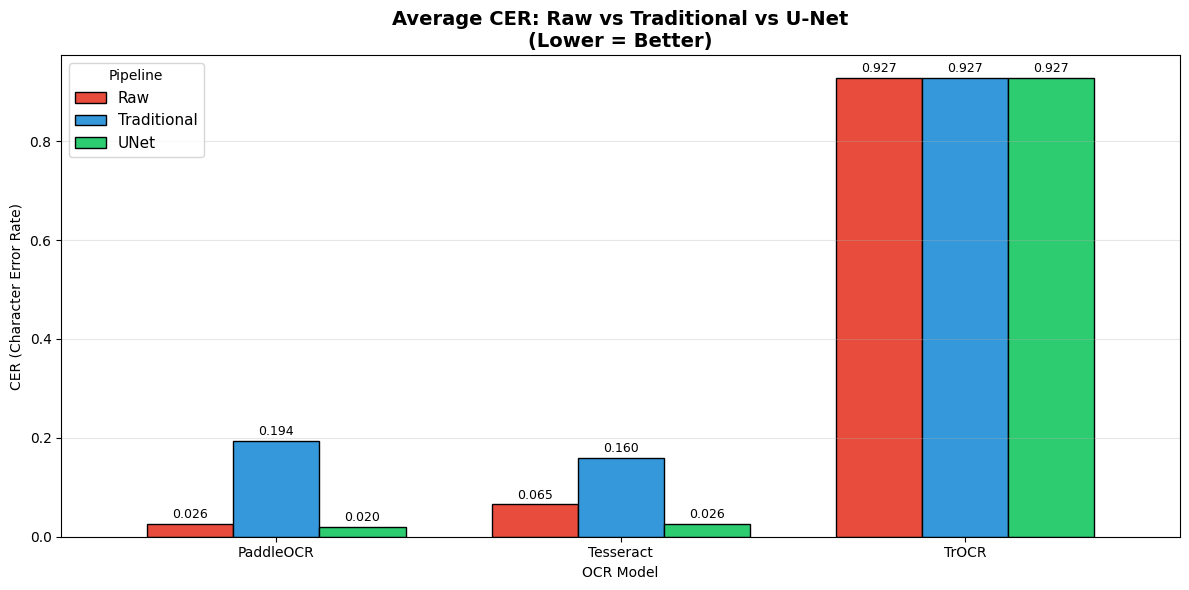

In [13]:
# Bar chart: CER trung binh theo OCR Model x Pipeline
fig, ax = plt.subplots(figsize=(12, 6))
pivot_plot = df.pivot_table(values='cer', index='ocr_model', columns='pipeline', aggfunc='mean')
pivot_plot = pivot_plot[['Raw', 'Traditional', 'UNet']]

colors = {'Raw': '#e74c3c', 'Traditional': '#3498db', 'UNet': '#2ecc71'}
pivot_plot.plot(kind='bar', ax=ax, color=[colors[c] for c in pivot_plot.columns],
                edgecolor='black', width=0.75)
ax.set_title('Average CER: Raw vs Traditional vs U-Net\n(Lower = Better)', fontsize=14, fontweight='bold')
ax.set_ylabel('CER (Character Error Rate)')
ax.set_xlabel('OCR Model')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title='Pipeline', fontsize=11)
ax.grid(axis='y', alpha=0.3)

# Ghi gia tri len moi cot
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=9, padding=2)

plt.tight_layout()
plt.show()

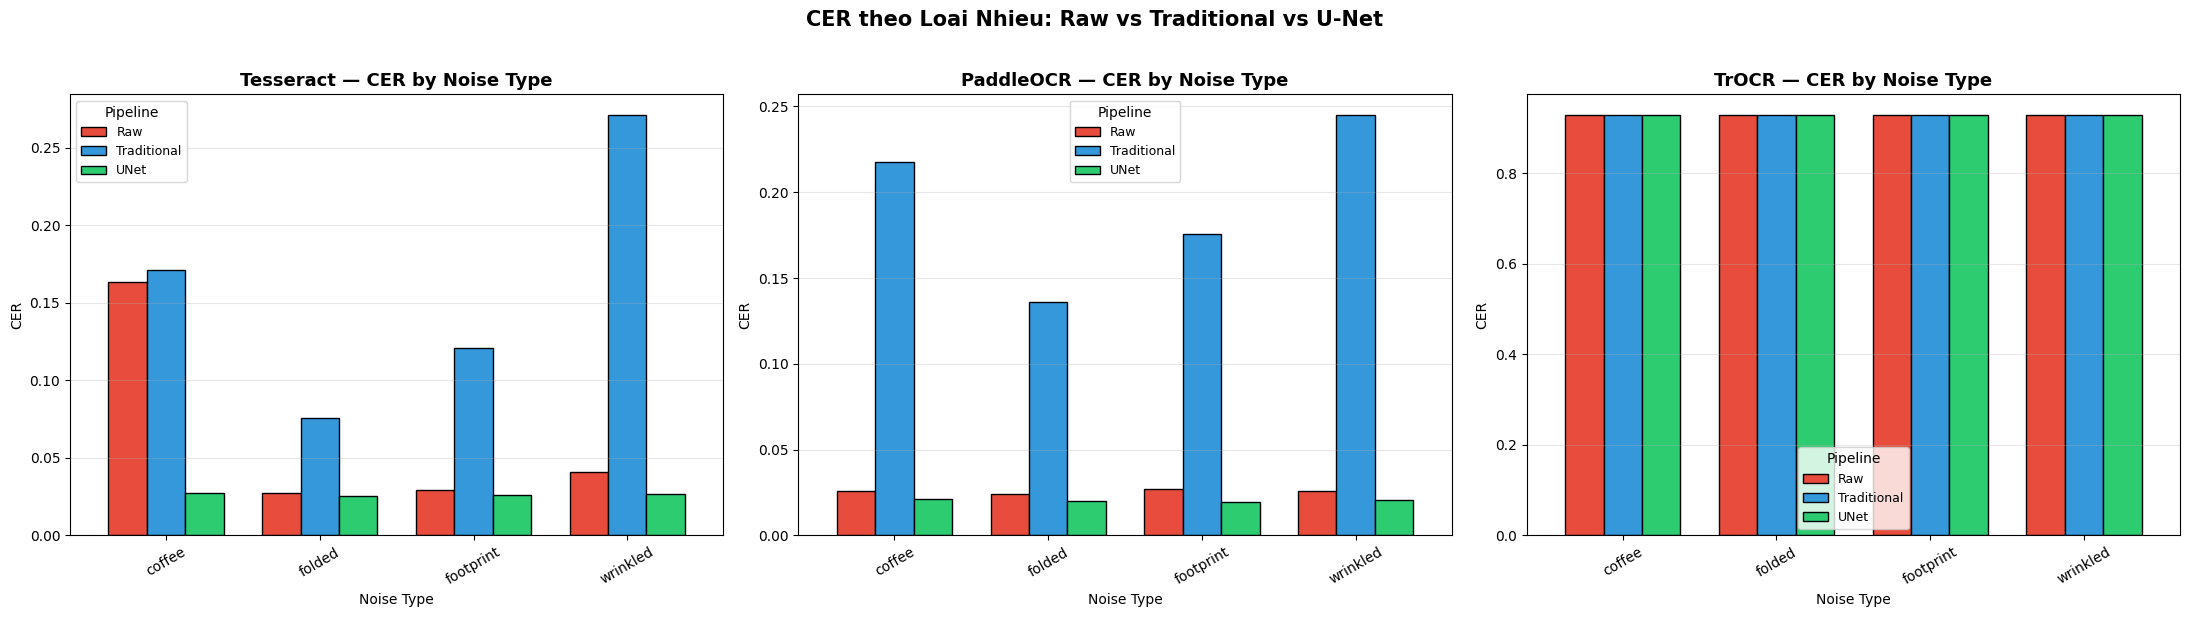

In [14]:
# Grouped bar chart: CER theo Noise Type cho tung OCR model
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
colors_list = ['#e74c3c', '#3498db', '#2ecc71']

for ax, ocr_name in zip(axes, ocr_models):
    sub = df[df['ocr_model'] == ocr_name]
    piv = sub.pivot_table(values='cer', index='noise_type', columns='pipeline', aggfunc='mean')
    piv = piv[['Raw', 'Traditional', 'UNet']]
    piv.plot(kind='bar', ax=ax, color=colors_list, edgecolor='black', width=0.75)
    ax.set_title(f'{ocr_name} — CER by Noise Type', fontsize=13, fontweight='bold')
    ax.set_ylabel('CER')
    ax.set_xlabel('Noise Type')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
    ax.legend(title='Pipeline', fontsize=9)
    ax.grid(axis='y', alpha=0.3)

plt.suptitle('CER theo Loai Nhieu: Raw vs Traditional vs U-Net', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

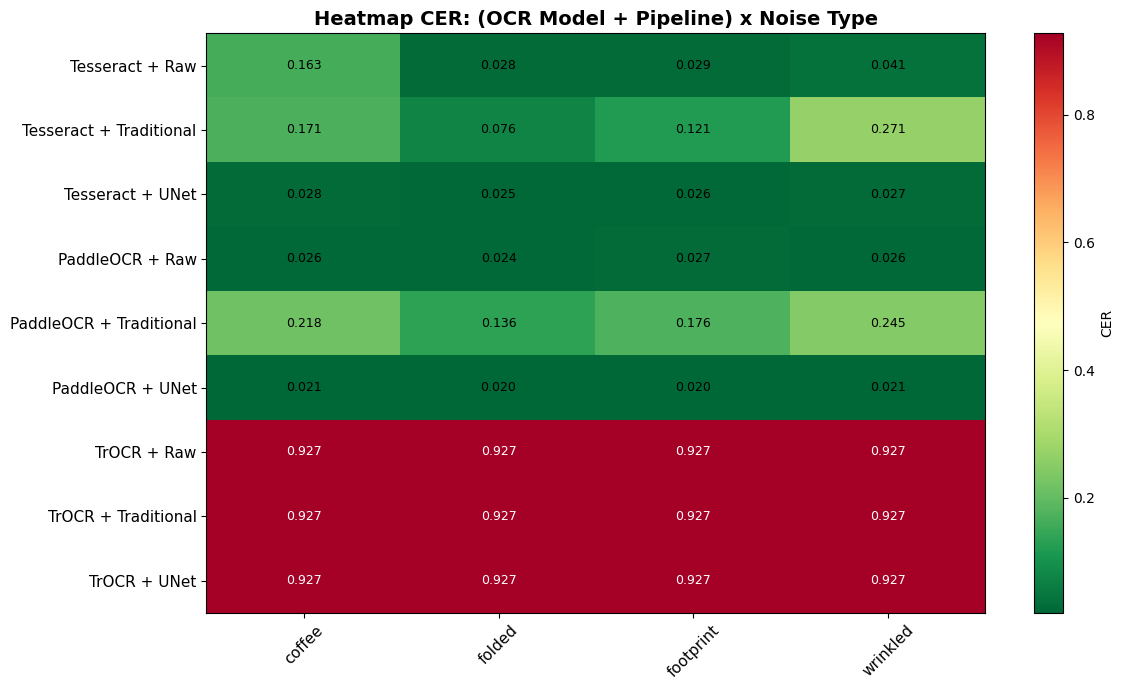

In [15]:
# Heatmap: CER cho tung to hop (OCR_Model+Pipeline) x Noise_Type
fig, ax = plt.subplots(figsize=(12, 7))

# Tao label gop
df['combo'] = df['ocr_model'] + ' + ' + df['pipeline']
piv = df.pivot_table(values='cer', index='combo', columns='noise_type', aggfunc='mean')

# Sap xep
order = []
for ocr in ocr_models:
    for pipe in pipelines:
        order.append(f'{ocr} + {pipe}')
piv = piv.reindex([o for o in order if o in piv.index])

im = ax.imshow(piv.values, cmap='RdYlGn_r', aspect='auto')
ax.set_xticks(range(len(piv.columns)))
ax.set_xticklabels(piv.columns, rotation=45, fontsize=11)
ax.set_yticks(range(len(piv.index)))
ax.set_yticklabels(piv.index, fontsize=11)
ax.set_title('Heatmap CER: (OCR Model + Pipeline) x Noise Type', fontsize=14, fontweight='bold')

# Ghi so len o
for i in range(len(piv.index)):
    for j in range(len(piv.columns)):
        ax.text(j, i, f'{piv.values[i,j]:.3f}', ha='center', va='center', fontsize=9,
                color='white' if piv.values[i,j] > 0.5 else 'black')

plt.colorbar(im, ax=ax, label='CER')
plt.tight_layout()
plt.show()

## 11. So sánh Trực quan (Visual Comparison)

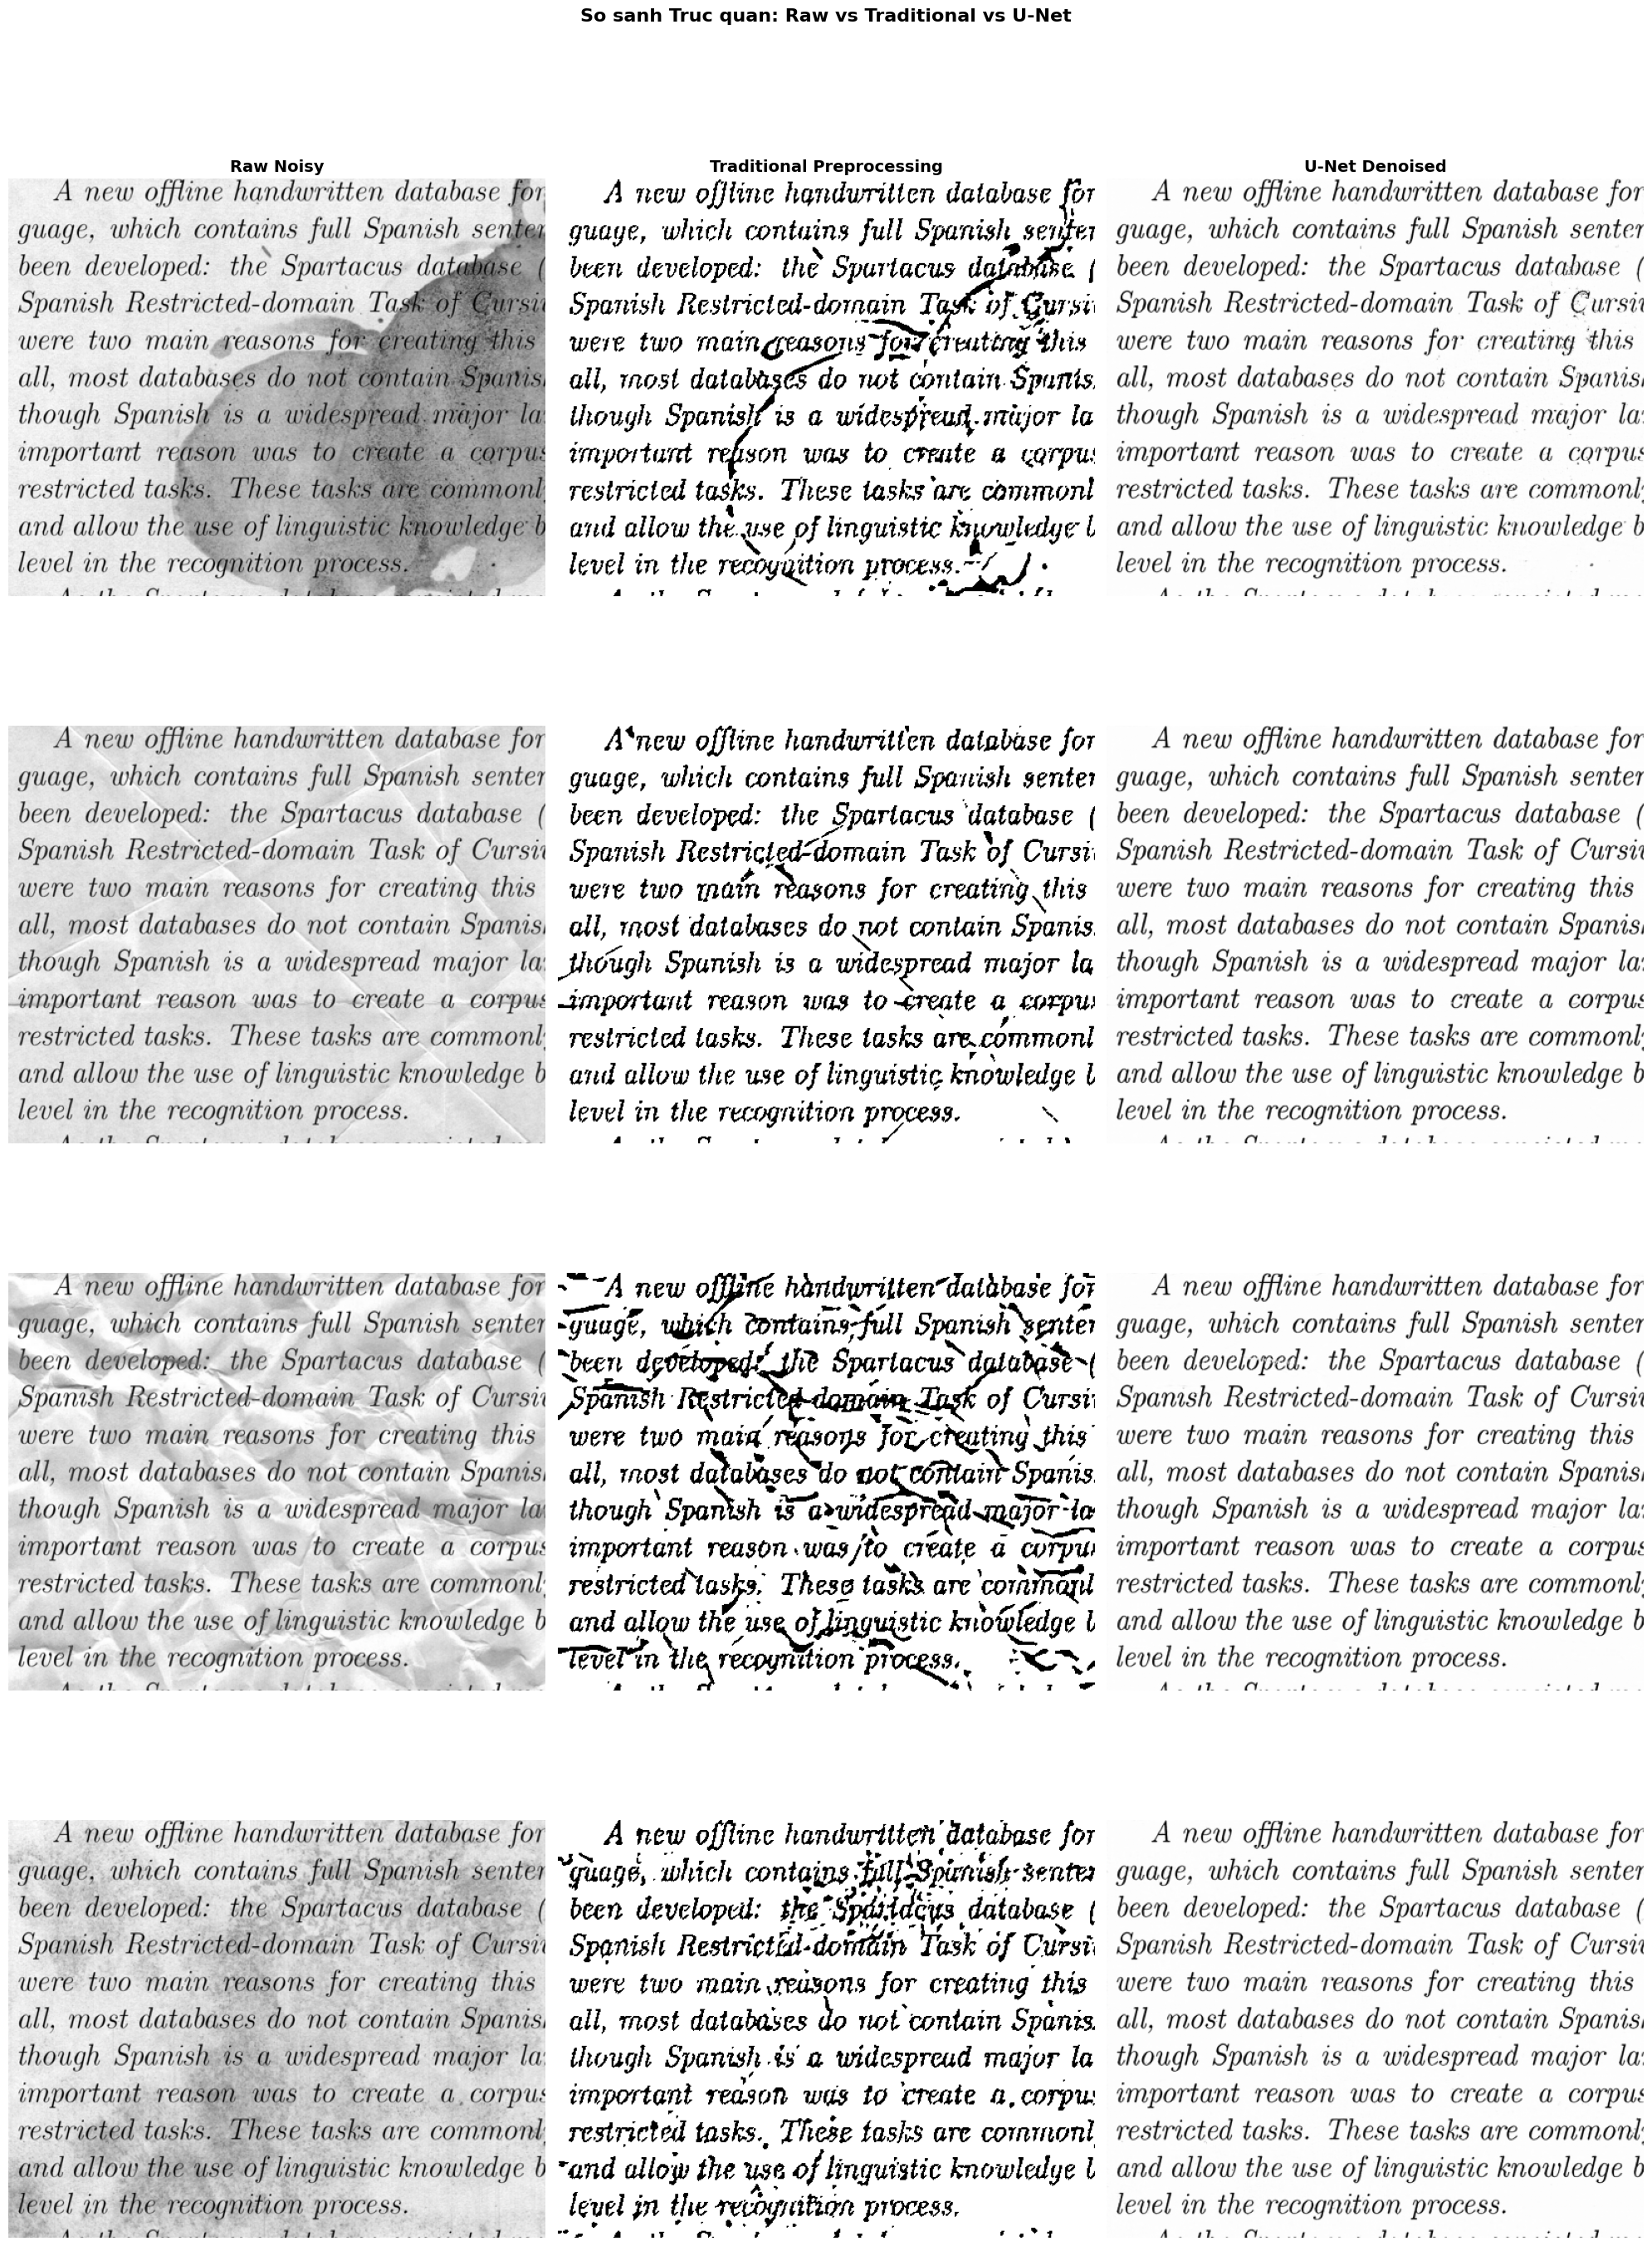

In [16]:
# Hien thi 4 mau (1 mau/loai nhieu): Raw vs Traditional vs U-Net
samples = ['FontLre_Noisec_TE.png', 'FontLre_Noisef_TE.png',
           'FontLre_Noisew_TE.png', 'FontLre_Noisep_TE.png']
noise_labels = ['Coffee Stains', 'Folded Sheets', 'Wrinkled', 'Footprints']

fig, axes = plt.subplots(4, 3, figsize=(20, 28))
axes[0, 0].set_title('Raw Noisy', fontsize=14, fontweight='bold')
axes[0, 1].set_title('Traditional Preprocessing', fontsize=14, fontweight='bold')
axes[0, 2].set_title('U-Net Denoised', fontsize=14, fontweight='bold')

for i, (fname, nlabel) in enumerate(zip(samples, noise_labels)):
    fpath = os.path.join(SIMULATED_NOISY, fname)
    if not os.path.exists(fpath):
        continue
    img = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)
    trad = preprocess_traditional(img)
    unet_out = unet_denoise(img)

    axes[i, 0].imshow(img, cmap='gray')
    axes[i, 0].set_ylabel(nlabel, fontsize=13, fontweight='bold')
    axes[i, 0].axis('off')
    axes[i, 1].imshow(trad['cleaned'], cmap='gray')
    axes[i, 1].axis('off')
    axes[i, 2].imshow(unet_out, cmap='gray')
    axes[i, 2].axis('off')

plt.suptitle('So sanh Truc quan: Raw vs Traditional vs U-Net', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 12. Kết luận & Xuất kết quả

In [17]:
# Bang ket luan cuoi cung
print('=' * 80)
print('KET LUAN CUOI CUNG')
print('=' * 80)

final_pivot = df.pivot_table(values=['cer', 'wer'], index='ocr_model', columns='pipeline', aggfunc='mean')
print('\nCER trung binh:')
print(final_pivot['cer'][['Raw', 'Traditional', 'UNet']].round(4).to_string())
print('\nWER trung binh:')
print(final_pivot['wer'][['Raw', 'Traditional', 'UNet']].round(4).to_string())

# Tim to hop tot nhat
best = df.groupby(['ocr_model', 'pipeline'])['cer'].mean().idxmin()
best_cer = df.groupby(['ocr_model', 'pipeline'])['cer'].mean().min()
print(f'\n>>> TO HOP TOT NHAT: {best[0]} + {best[1]} pipeline (CER = {best_cer:.4f})')

# Luu ket qua
df.to_csv(os.path.join(OUTPUT_DIR, 'unet_vs_trad_results.csv'), index=False)
print(f'\nKet qua da luu tai: {OUTPUT_DIR}/unet_vs_trad_results.csv')

KET LUAN CUOI CUNG

CER trung binh:
pipeline      Raw  Traditional    UNet
ocr_model                             
PaddleOCR  0.0258       0.1936  0.0204
Tesseract  0.0652       0.1598  0.0265
TrOCR      0.9274       0.9274  0.9274

WER trung binh:
pipeline      Raw  Traditional    UNet
ocr_model                             
PaddleOCR  0.1073       0.5240  0.0745
Tesseract  0.1856       0.4437  0.0968
TrOCR      0.9894       0.9894  0.9894

>>> TO HOP TOT NHAT: PaddleOCR + UNet pipeline (CER = 0.0204)

Ket qua da luu tai: /content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/unet_vs_trad_results/unet_vs_trad_results.csv


## 13. Run Best Model on Real Noisy Images (U-Net + PaddleOCR)

Sử dụng pipeline tốt nhất vào 72 real noisy images:
**Ảnh thực tế (Real Noisy) → Preprocessing (U-Net) → Recognition (PaddleOCR)**

Processing 72 real noisy images with U-Net + PaddleOCR...



Real Noisy Inference:   0%|          | 0/72 [00:00<?, ?it/s]

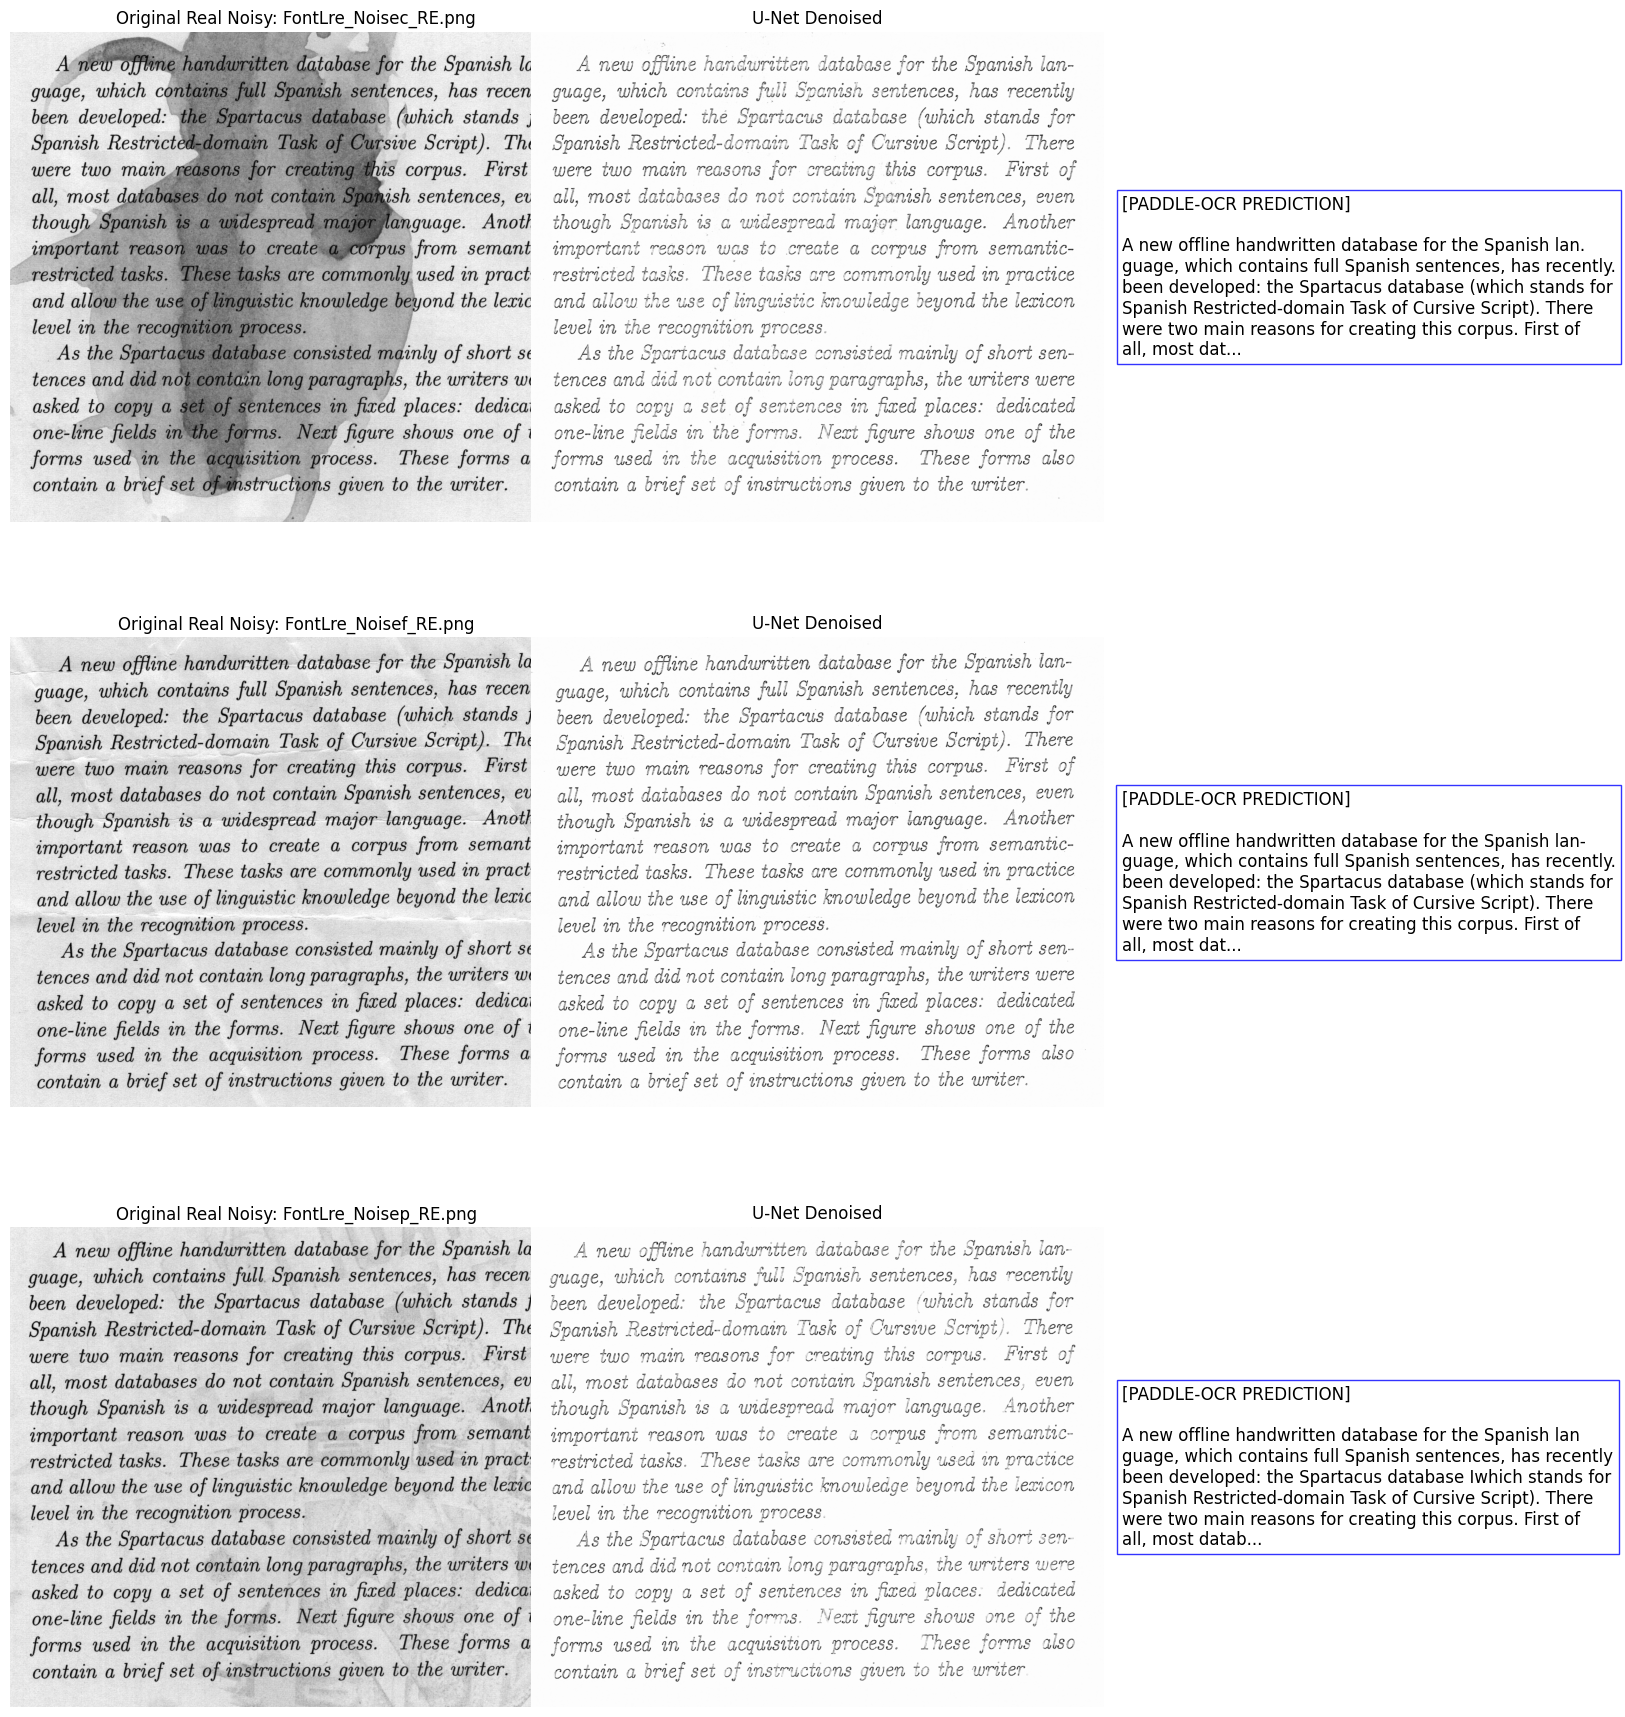


[Hoan thanh] Da luu text du doan cua 72 anh vao: /content/drive/MyDrive/DAT301_SE190840_NguyenPhuongVu_Assigments/OCR_Testing/unet_vs_trad_results/Real_UNet_PaddleOCR_Results


In [18]:
real_files = sorted(glob.glob(os.path.join(REAL_NOISY, '*.png')))
print(f'Processing {len(real_files)} real noisy images with U-Net + PaddleOCR...\n')

real_out_dir = os.path.join(OUTPUT_DIR, 'Real_UNet_PaddleOCR_Results')
os.makedirs(real_out_dir, exist_ok=True)

# Hien thi 3 anh dau tien de kiem tra truc quan
n_show = min(3, len(real_files))
fig, axes = plt.subplots(n_show, 2, figsize=(16, 6 * n_show))

for i, fpath in enumerate(tqdm(real_files, desc='Real Noisy Inference')):
    fname = os.path.basename(fpath)

    # 1. Doc anh goc
    img_raw = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)

    # 2. Tien xu ly bang U-Net (Patch-based de giu do net)
    unet_out = unet_denoise(img_raw)

    # Luu anh U-Net tam de dua vao PaddleOCR
    tmp_path = f'/tmp/real_unet_{fname}'
    cv2.imwrite(tmp_path, unet_out)

    # 3. Nhan dang bang PaddleOCR
    text_pred = ocr_paddleocr(tmp_path)

    # Luu ket qua Text
    txt_name = fname.replace('.png', '.txt')
    with open(os.path.join(real_out_dir, txt_name), 'w', encoding='utf-8') as txt_f:
        txt_f.write(text_pred)

    # Truc quan hoa (chi hien thi n_show anh)
    if i < n_show:
        axes[i, 0].imshow(img_raw, cmap='gray')
        axes[i, 0].set_title(f'Original Real Noisy: {fname}', fontsize=12)
        axes[i, 0].axis('off')

        axes[i, 1].imshow(unet_out, cmap='gray')
        axes[i, 1].set_title('U-Net Denoised', fontsize=12)
        axes[i, 1].axis('off')

        # In text du doan ra canh anh (su dung text box)
        axes[i, 1].text(unet_out.shape[1] + 50, unet_out.shape[0]//2,
                        f"[PADDLE-OCR PREDICTION]\n\n{text_pred[:300]}...",
                        fontsize=12, verticalalignment='center',
                        bbox=dict(facecolor='white', alpha=0.8, edgecolor='blue'))

plt.tight_layout()
plt.show()

print(f'\n[Hoan thanh] Da luu text du doan cua {len(real_files)} anh vao: {real_out_dir}')